# The CNN object tour: what the robot's camera saw

Extra demo world `webots_project/worlds/cnn_objects.wbt` (not part of the main results). The e-puck drives to three coloured blocks and five Webots objects (truck, horse, car, paper boat, deer) and photographs each object three times: at its normal viewing distance, 15% closer and 15% further. The photos are in `webots_object_tour/`.

This notebook runs the robot's own **int8 CIFAR-10 CNN** on those photos, with the same centre square crop and 32×32 resize the robot uses, so the answers match what the robot prints (up to small rounding differences). The three answers for each object then vote.

In [1]:
import pathlib, re
from collections import defaultdict
import numpy as np, cv2 as cv, matplotlib.pyplot as plt

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
EXPECTED = {"truck": "truck", "horse": "horse", "car": "automobile", "boat": "ship", "deer": "deer"}
IMAGES = pathlib.Path("webots_object_tour")
MODEL = pathlib.Path("results/models/cifar10_cnn_int8.tflite")

try:  # the robot's runtime; Colab has TensorFlow instead
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    import tensorflow as tf
    Interpreter = tf.lite.Interpreter
interp = Interpreter(model_path=str(MODEL)); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

def centre_square(bgr):
    h, w = bgr.shape[:2]; s = min(h, w); y, x = (h - s) // 2, (w - s) // 2
    return bgr[y:y + s, x:x + s]

def predict(bgr):
    rgb = cv.cvtColor(centre_square(bgr), cv.COLOR_BGR2RGB)
    x = (cv.resize(rgb, (32, 32), interpolation=cv.INTER_AREA).astype(np.float32) / 255.0)[None]
    scale, zero = inp["quantization"]
    interp.set_tensor(inp["index"], np.round(x / scale + zero).clip(-128, 127).astype(inp["dtype"]))
    interp.invoke()
    q = interp.get_tensor(out["index"])[0].astype(np.float32)
    s, z = out["quantization"]; logits = (q - z) * s
    p = np.exp(logits - logits.max()); return p / p.sum()

files = sorted(f for f in IMAGES.glob("*.png") if "block" not in f.name)
assert len(files) == 15, f"expected 15 object photos (5 objects x 3 views), found {len(files)}"
rows = []
for f in files:
    name, view = re.match(r"\d+_(\w+?)_view(\d)", f.stem).groups()
    p = predict(cv.imread(str(f))); k = int(p.argmax())
    rows.append((name, int(view), CLASS_NAMES[k], float(p[k]), f))
for name, view, label, conf, _ in rows:
    print(f"{name:6s} view {view}: {label:10s} {conf:5.0%}")

truck  view 1: truck        66%
truck  view 2: truck        90%
truck  view 3: truck        87%
horse  view 1: airplane     80%
horse  view 2: horse       100%
horse  view 3: horse        87%
car    view 1: automobile  100%
car    view 2: automobile   99%
car    view 3: automobile   99%
boat   view 1: airplane     79%
boat   view 2: airplane     75%
boat   view 3: airplane     96%
deer   view 1: deer         91%
deer   view 2: deer         95%
deer   view 3: deer         61%


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Every photo, and the verdict after the vote

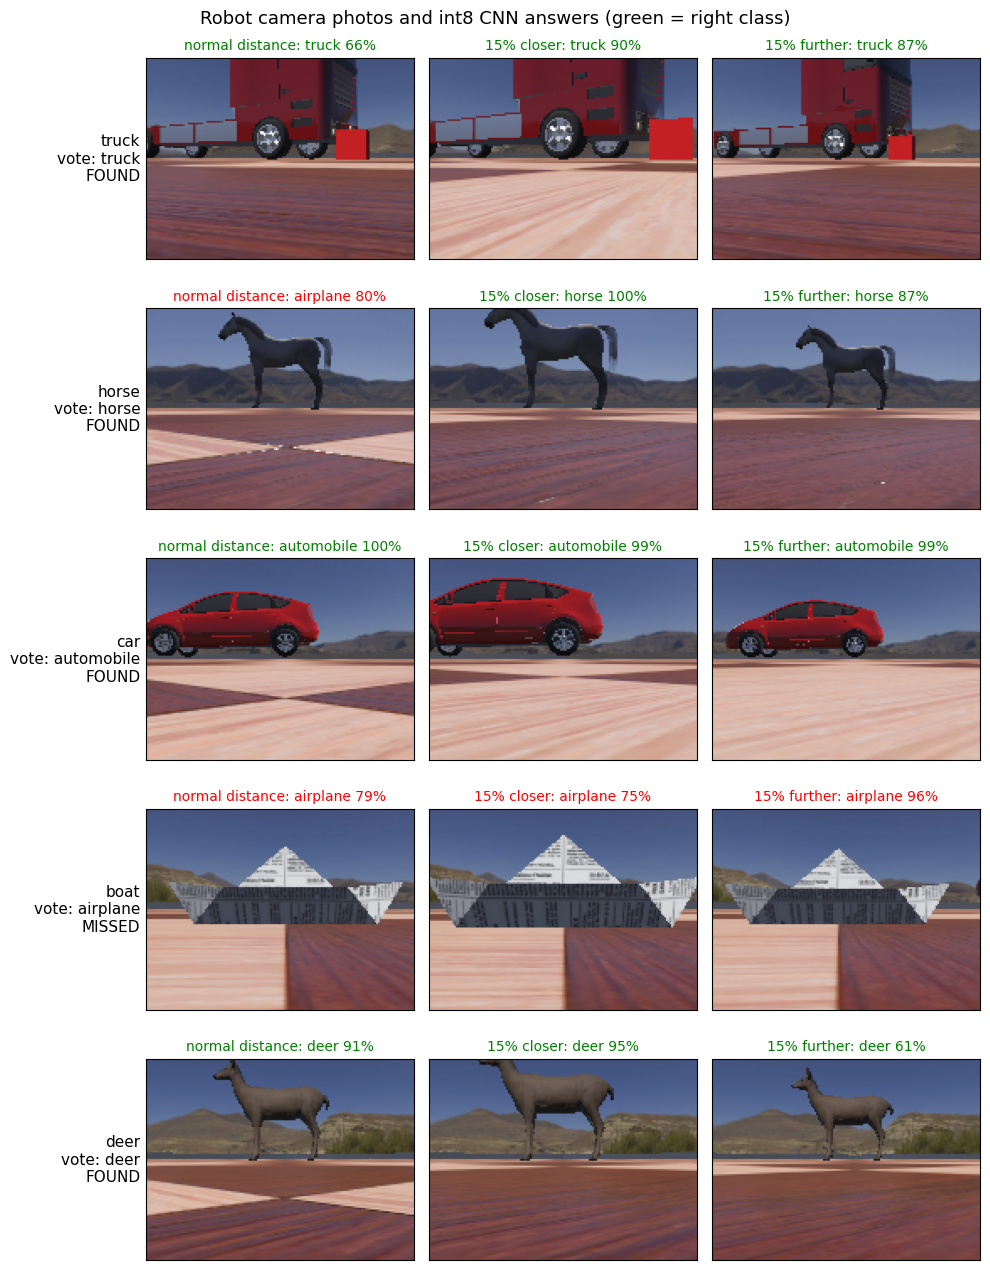

In [2]:
order = ["truck", "horse", "car", "boat", "deer"]
fig, axes = plt.subplots(len(order), 3, figsize=(10, 13))
view_names = {1: "normal distance", 2: "15% closer", 3: "15% further"}
for r, name in enumerate(order):
    votes = defaultdict(float)
    for name_, view, label, conf, f in rows:
        if name_ != name: continue
        ax = axes[r, view - 1]
        ax.imshow(cv.cvtColor(cv.imread(str(f)), cv.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([])
        ok = label == EXPECTED[name]
        ax.set_title(f"{view_names[view]}: {label} {conf:.0%}", color="green" if ok else "red", fontsize=10)
        votes[label] += conf
    best = max(votes, key=votes.get)
    axes[r, 0].set_ylabel(f"{name}\nvote: {best}\n{'FOUND' if best == EXPECTED[name] else 'MISSED'}",
                          fontsize=11, rotation=0, ha="right", va="center")
fig.suptitle("Robot camera photos and int8 CNN answers (green = right class)", fontsize=13)
fig.tight_layout(); plt.show()

## What this shows

- The truck, horse, car and deer are named correctly after the vote. The car is right in every photo, at 99–100%.
- The **paper boat is called "airplane"**. It is a ship-like shape on a wooden floor with no water, and CIFAR-10's ships are almost always on the sea. That is the same shortcut learning as the background-swap test in `webots_animals.ipynb`: the CNN uses the setting as much as the object.
- Single photos can be wrong (one horse photo says airplane), which is why the robot takes three and lets them vote.
- The three coloured blocks are checked by HSV colour detection, not the CNN, so they are not in this notebook.